# Türkiye TÜFE Enflasyon Tahmini – Zaman Serisi Analizi

**Hazırlayan:** Esma Nur Okşul – Sakarya Üniversitesi, Ekonometri

**Amaç:** Türkiye'nin aylık enflasyonunu SARIMA modeli ile tahmin etmek ve modelin başarısını basit bir karşılaştırma yöntemiyle (benchmark) ölçmek.

**Veri:** TCMB EVDS – Tüketici Fiyat Endeksi (2003=100), Genel, aylık, Ocak 2004 – Ocak 2026 (265 gözlem). TÜİK 2026'da baz yılını 2025=100'e değiştirdiği için 2003=100 serisi Ocak 2026'da sona ermektedir.

**Yöntem:** Logaritmik fark ile aylık enflasyon → ADF durağanlık testi → ACF/PACF → AIC ile SARIMA model seçimi → son 12 ay ile test → 6 aylık ileri tahmin.

## 1. Kütüphaneler ve veri

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (11, 4)

URL = "https://raw.githubusercontent.com/ecoesmanur/tufe-enflasyon-tahmini/main/tufe_2004_2026.csv"
try:
    df = pd.read_csv(URL)
except Exception:
    df = pd.read_csv("tufe_2004_2026.csv")   # dosya yerelde ise

df["tarih"] = pd.to_datetime(df["tarih"])
df = df.set_index("tarih").asfreq("MS")      # MS = aylık, ayın ilk günü
df.tail()

,tufe
tarih,
2025-09-01,3367.22
2025-10-01,3453.09
2025-11-01,3482.96
2025-12-01,3513.87
2026-01-01,3683.83


## 2. TÜFE endeksinin seyri
Endeks sürekli artıyor ve özellikle 2021 sonrasında artış hızlanıyor. Logaritmik eksende bakmak, artış **hızını** (eğimi) görmemizi kolaylaştırır.

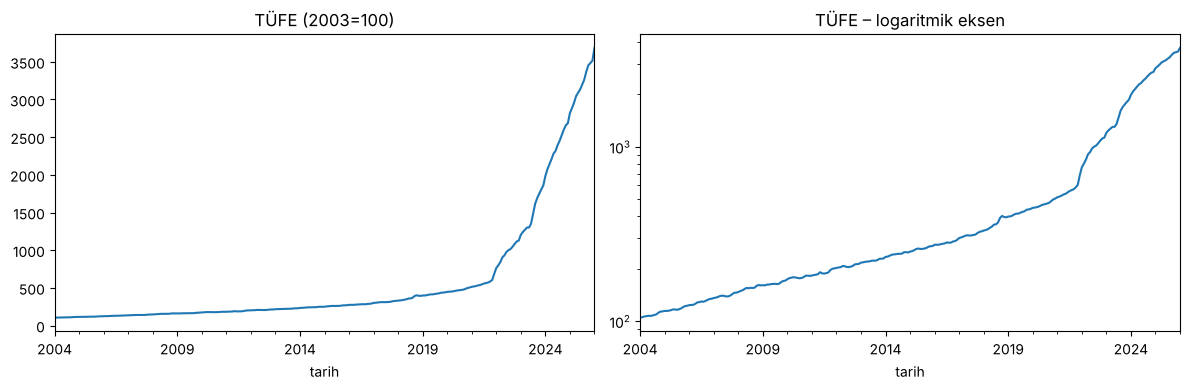

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["tufe"].plot(ax=ax[0], title="TÜFE (2003=100)")
df["tufe"].plot(ax=ax[1], logy=True, title="TÜFE – logaritmik eksen")
plt.tight_layout(); plt.show()

## 3. Aylık ve yıllık enflasyon
- **Aylık enflasyon** = 100 × [ln(TÜFE_t) − ln(TÜFE_t−1)]  (log fark, yüzde değişime çok yakındır)
- **Yıllık enflasyon** = 100 × (TÜFE_t / TÜFE_t−12 − 1)

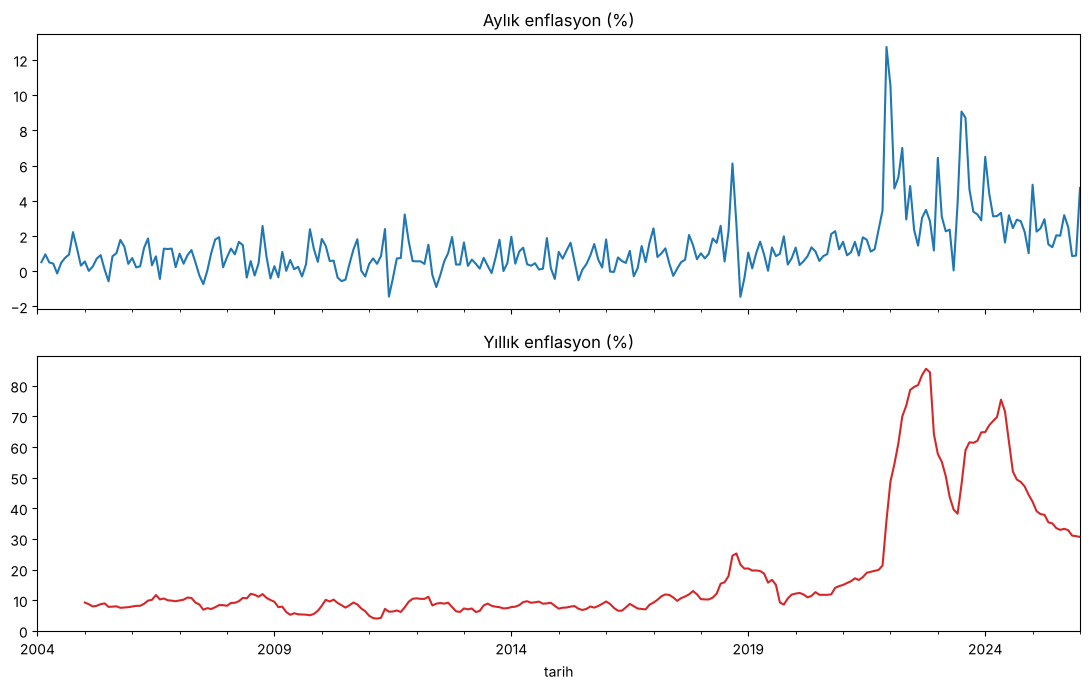

Son yıllık enflasyon (Ocak 2026): 30.6%
En yüksek yıllık enflasyon: 85.5% (2022-10)


In [3]:
df["aylik"] = 100 * np.log(df["tufe"]).diff()
df["yillik"] = 100 * (df["tufe"] / df["tufe"].shift(12) - 1)

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
df["aylik"].plot(ax=ax[0], title="Aylık enflasyon (%)")
df["yillik"].plot(ax=ax[1], title="Yıllık enflasyon (%)", color="C3")
plt.tight_layout(); plt.show()

print("Son yıllık enflasyon (Ocak 2026): %.1f%%" % df["yillik"].iloc[-1])
print("En yüksek yıllık enflasyon: %.1f%% (%s)" % (df["yillik"].max(), df["yillik"].idxmax().strftime("%Y-%m")))

## 4. Durağanlık testi (ADF)
ARIMA modelleri **durağan** seri ister. ADF testinde H0: "seride birim kök var (durağan değil)".
p-değeri 0.05'ten küçükse H0 reddedilir ve seri durağan kabul edilir.

In [4]:
def adf(seri, ad):
    p = adfuller(seri.dropna())[1]
    print(f"{ad:30s} p-değeri = {p:.3f}  ->  {'durağan' if p < 0.05 else 'durağan değil'}")

adf(np.log(df["tufe"]), "log(TÜFE)")
adf(df["aylik"], "Aylık enflasyon")

log(TÜFE)                      p-değeri = 1.000  ->  durağan değil
Aylık enflasyon                p-değeri = 0.350  ->  durağan değil


**Yorum:** Log TÜFE açıkça durağan değil (beklenen sonuç). Aylık enflasyonda da ADF %5'te birim kökü reddedemiyor; bunun temel nedeni 2021 sonrası enflasyon seviyesinin kalıcı olarak yükselmesi (yapısal kırılma). Bu, modelin sınırlılığı olarak not edilmeli. Tahmin için aylık enflasyonu kullanmaya devam ediyoruz, çünkü sonraki adımda modeli basit bir yöntemle karşılaştırıp gerçekten işe yarayıp yaramadığını test edeceğiz.

## 5. ACF ve PACF
Otokorelasyon grafikleri, modelin AR (p) ve MA (q) derecelerine dair ipucu verir. 12. gecikmedeki çıkıntılar **mevsimselliğe** işaret eder.

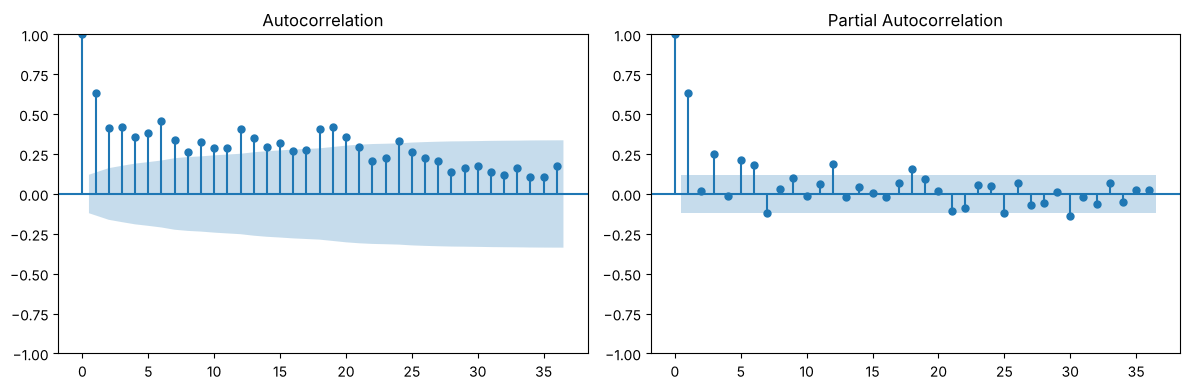

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(df["aylik"].dropna(), lags=36, ax=ax[0])
plot_pacf(df["aylik"].dropna(), lags=36, ax=ax[1])
plt.tight_layout(); plt.show()

## 6. Eğitim / test ayrımı ve model seçimi
- **Eğitim:** Şubat 2004 – Ocak 2025
- **Test:** Şubat 2025 – Ocak 2026 (son 12 ay, model bu veriyi hiç görmüyor)

Farklı SARIMA(p,0,q)(P,0,0)[12] modellerini deneyip **AIC** değeri en düşük olanı seçiyoruz.

In [6]:
y = df["aylik"].dropna()
egitim = y[:"2025-01"]
test   = y["2025-02":]

sonuclar = []
for p in range(3):
    for q in range(3):
        for P in range(2):
            m = SARIMAX(egitim, order=(p, 0, q), seasonal_order=(P, 0, 0, 12), trend="c").fit(disp=False)
            sonuclar.append({"p": p, "q": q, "P": P, "AIC": round(m.aic, 1)})

tablo = pd.DataFrame(sonuclar).sort_values("AIC")
tablo.head()

,p,q,P,AIC
11,1,2,1,835.5
17,2,2,1,837.4
10,1,2,0,838.0
16,2,2,0,839.9
15,2,1,1,850.1


In [7]:
en_iyi = tablo.iloc[0]
order = (int(en_iyi.p), 0, int(en_iyi.q)); sorder = (int(en_iyi.P), 0, 0, 12)
model = SARIMAX(egitim, order=order, seasonal_order=sorder, trend="c").fit(disp=False)
print("Seçilen model: SARIMA", order, sorder)
print(model.summary().tables[1])

Seçilen model: SARIMA (1, 0, 2) (1, 0, 0, 12)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0241      0.029      0.828      0.408      -0.033       0.081
ar.L1          0.9810      0.017     58.626      0.000       0.948       1.014
ma.L1         -0.3681      0.045     -8.211      0.000      -0.456      -0.280
ma.L2         -0.4679      0.048     -9.772      0.000      -0.562      -0.374
ar.S.L12       0.1372      0.042      3.283      0.001       0.055       0.219
sigma2         1.5280      0.052     29.286      0.000       1.426       1.630


## 7. Test performansı
Modeli iki basit yöntemle karşılaştırıyoruz:
- **Naif-1:** Gelecek her ay = son ayın enflasyonu
- **Naif-12:** Gelecek her ay = son 12 ayın ortalaması

Ölçüt: **RMSE** (hataların karekök ortalaması, düşük = iyi).

,RMSE
SARIMA,1.235
Naif-12 (12 ay ort.),1.248
Naif-1 (son ay),2.874


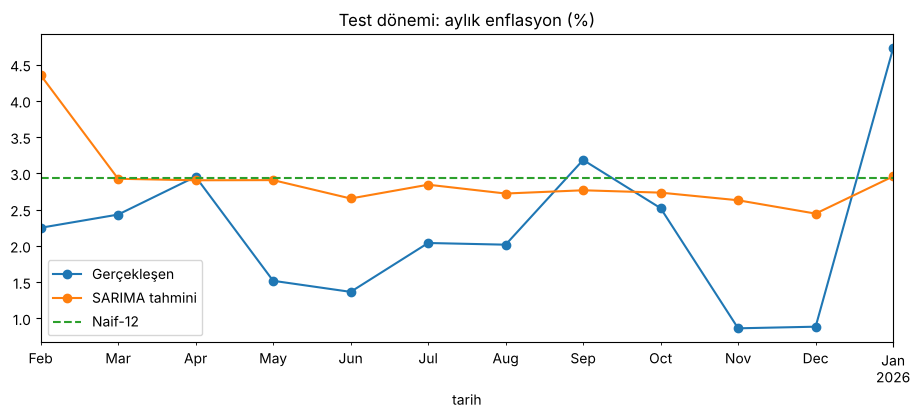

In [8]:
tahmin = model.forecast(len(test))
naif1  = pd.Series(egitim.iloc[-1], index=test.index)
naif12 = pd.Series(egitim[-12:].mean(), index=test.index)

rmse = lambda t: np.sqrt(((t - test) ** 2).mean())
perf = pd.DataFrame({"RMSE": [rmse(tahmin), rmse(naif12), rmse(naif1)]},
                    index=["SARIMA", "Naif-12 (12 ay ort.)", "Naif-1 (son ay)"]).round(3)
display(perf)

ax = test.plot(label="Gerçekleşen", marker="o")
tahmin.plot(ax=ax, label="SARIMA tahmini", marker="o")
naif12.plot(ax=ax, label="Naif-12", ls="--")
ax.set_title("Test dönemi: aylık enflasyon (%)"); ax.legend(); plt.show()

**Yorum:** SARIMA, "son ay" yöntemine göre çok daha iyi; ancak "son 12 ay ortalaması" yöntemini yalnızca çok az geçiyor. Yani model enflasyonun genel seviyesini yakalıyor ama ani aylık sıçramaları (ör. Ocak ayı fiyat ayarlamaları) tahmin etmekte zorlanıyor. Enflasyon gibi politika ve şoklardan etkilenen bir seride bu beklenen bir sonuç.

## 8. Gelecek 6 ay tahmini
Modeli tüm veriyle yeniden kurup Şubat – Temmuz 2026 için aylık enflasyon tahmini ve %95 güven aralığı üretiyoruz.

,tahmin_%,alt_%95,ust_%95
2026-02,3.42,1.01,5.84
2026-03,2.29,-0.52,5.11
2026-04,2.36,-0.47,5.20
2026-05,2.10,-0.76,4.95
2026-06,2.05,-0.82,4.92
2026-07,2.15,-0.74,5.04


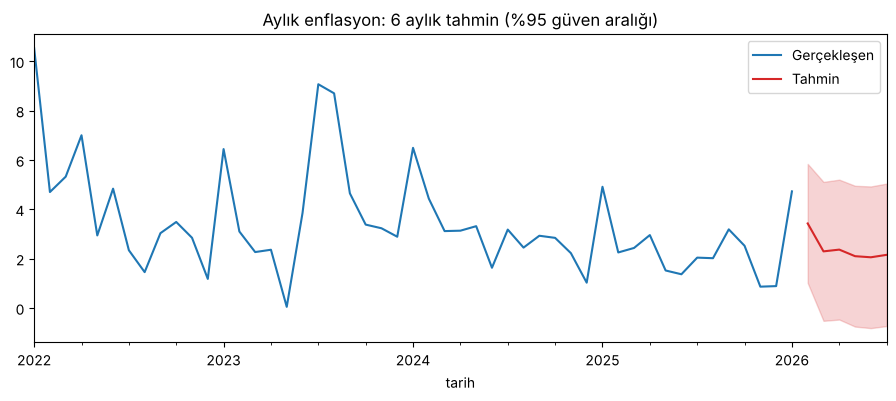

In [9]:
final = SARIMAX(y, order=order, seasonal_order=sorder, trend="c").fit(disp=False)
f = final.get_forecast(6)
ileri = pd.DataFrame({"tahmin_%": f.predicted_mean, 
                      "alt_%95": f.conf_int().iloc[:, 0], 
                      "ust_%95": f.conf_int().iloc[:, 1]}).round(2)
ileri.index = ileri.index.strftime("%Y-%m")
display(ileri)

ax = y["2022":].plot(label="Gerçekleşen")
f.predicted_mean.plot(ax=ax, label="Tahmin", color="C3")
ax.fill_between(f.conf_int().index, f.conf_int().iloc[:, 0], f.conf_int().iloc[:, 1], color="C3", alpha=0.2)
ax.set_title("Aylık enflasyon: 6 aylık tahmin (%95 güven aralığı)"); ax.legend(); plt.show()

## 9. Sonuç ve sınırlılıklar
- Türkiye'de yıllık TÜFE enflasyonu Ocak 2026 itibarıyla yaklaşık %30,6 seviyesindedir (Ocak 2025: %42,1).
- AIC ile seçilen SARIMA modeli, test döneminde naif yöntemlere göre daha düşük hata vermiştir, ancak 12 aylık ortalamaya göre fark küçüktür.
- **Sınırlılıklar:** 2021 sonrası yapısal kırılma, tek değişkenli model (faiz, kur gibi açıklayıcı değişkenler yok), Ocak aylarındaki yönetilen fiyat ayarlamaları.
- **Geliştirme fikirleri:** USD/TRY kuru ve politika faizini ekleyerek SARIMAX modeli kurmak; yalnızca 2018 sonrası veriyle modeli yeniden tahmin etmek; 2025=100 bazlı yeni TÜFE serisiyle tahminleri karşılaştırmak.